# 1. Setup e Parametri del Problema

In [1]:
import math
import random
import time
import matplotlib.pyplot as plt

random.seed(42)  # Mappa casuale a ogni esecuzione

num_clienti = 60
num_drones = 2
speed_truck = 25.0  # mph
speed_drone = 25.0  # mph
max_endurance_min = 30.0  # min
max_radius = (max_endurance_min / 60.0) * speed_drone / 2.0  # 6.25 miglia

In [2]:
C = list(range(1, num_clienti + 1))
coords = {0: (0, 0), num_clienti + 1: (0, 0)}

clienti_idonei_drone = []  # Lista di controllo per l'idoneità fisica

print(f"--- GENERAZIONE ISTANZA ({num_clienti} Clienti) ---")
for i in C:
    x, y = random.uniform(-8, 8), random.uniform(-8, 8)
    coords[i] = (x, y)
    dist = math.hypot(x, y)
    weight_ok = random.random() < 0.8
    
    if dist <= max_radius and weight_ok:
        clienti_idonei_drone.append(i)

--- GENERAZIONE ISTANZA (60 Clienti) ---


# 2. Funzioni Matematiche e di Servizio

In [3]:

def dist_euclidea(i, j):
    return math.hypot(coords[i][0] - coords[j][0], coords[i][1] - coords[j][1])

def tempo_camion(i, j):
    return (dist_euclidea(i, j) / speed_truck) * 60.0

def tempo_volo(i):
    return (dist_euclidea(0, i) / speed_drone) * 60.0 * 2  # Andata + Ritorno

# 3. Moduli Algoritmici (Componenti dell'Euristica)

In [4]:
def solve_tsp_nearest_neighbor(clienti_assegnati):
    """Calcola il percorso del camion usando il Vicino Più Prossimo"""
    if not clienti_assegnati:
        return [0, num_clienti + 1], tempo_camion(0, num_clienti + 1)
        
    se_visitati = set()
    percorso = [0]
    tempo_totale = 0.0
    nodo_corrente = 0
    
    while len(se_visitati) < len(clienti_assegnati):
        prox_nodo = None
        min_dist = float('inf')
        
        for j in clienti_assegnati:
            if j not in se_visitati:
                t = tempo_camion(nodo_corrente, j)
                if t < min_dist:
                    min_dist = t
                    prox_nodo = j
                    
        percorso.append(prox_nodo)
        se_visitati.add(prox_nodo)
        tempo_totale += min_dist
        nodo_corrente = prox_nodo
        
    tempo_totale += tempo_camion(nodo_corrente, num_clienti + 1)
    percorso.append(num_clienti + 1)
    
    return percorso, tempo_totale

In [ ]:
def solve_pms_lpt(clienti_assegnati):
    """Ripartisce i clienti tra i droni usando la regola LPT"""
    tempi_droni = {v: 0.0 for v in range(1, num_drones + 1)}
    assegnazioni = {v: [] for v in range(1, num_drones + 1)}
    
    clienti_ordinati = sorted(clienti_assegnati, key=lambda i: tempo_volo(i), reverse=False)
    
    for c in clienti_ordinati:
        drone_libero = min(tempi_droni, key=tempi_droni.get)
        tempi_droni[drone_libero] += tempo_volo(c)
        assegnazioni[drone_libero].append(c)
        
    tempo_max_droni = max(tempi_droni.values()) if tempi_droni else 0.0
    return assegnazioni, tempi_droni, tempo_max_droni


# 4. Algoritmo Truck First, Drone Second

In [6]:
print("\n--- INIZIO EURISTICA: TRUCK FIRST, DRONE SECOND ---")
start_time = time.time()

# Configurazione Iniziale: TUTTI i clienti al camion, nessuno ai droni
miglior_C_truck = list(C)
miglior_C_second = []

percorso_iniziale, t_camion_iniziale = solve_tsp_nearest_neighbor(miglior_C_truck)
assegnazioni_iniziali, tempi_iniziali, t_droni_iniziale = solve_pms_lpt(miglior_C_second)

miglior_makespan = max(t_camion_iniziale, t_droni_iniziale)

print(f"Stato Iniziale (100% al Camion) -> Camion: {t_camion_iniziale:.2f} min | Droni: {t_droni_iniziale:.2f} min | Makespan: {miglior_makespan:.2f} min")

miglioramento = True
iterazione = 1

while miglioramento:
    miglioramento = False
    candidato_migliore = None
    nuovo_makespan_min = miglior_makespan
    
    # Scansioniamo i clienti attualmente sul camion per trovare candidati da spostare ai droni
    for c in miglior_C_truck:
        if c in clienti_idonei_drone:
            # Simula lo spostamento
            test_C_truck = [x for x in miglior_C_truck if x != c]
            test_C_second = miglior_C_second + [c]
            
            percorso_test, t_tt = solve_tsp_nearest_neighbor(test_C_truck)
            assegnazioni_test, dettagli_test, t_dt = solve_pms_lpt(test_C_second)
            
            test_makespan = max(t_tt, t_dt)
            
            # Cerchiamo lo spostamento che riduce maggiormente il Makespan globale
            if test_makespan < nuovo_makespan_min:
                nuovo_makespan_min = test_makespan
                candidato_migliore = c
                
    # Se lo spostamento migliore trovato riduce effettivamente il tempo totale, lo confermiamo
    if candidato_migliore is not None:
        miglior_C_truck.remove(candidato_migliore)
        miglior_C_second.append(candidato_migliore)
        miglior_makespan = nuovo_makespan_min
        miglioramento = True
        print(f"Iterazione {iterazione}: Spostato Cliente {candidato_migliore} ai Droni. Nuovo Makespan = {miglior_makespan:.2f} min")
        iterazione += 1

end_time = time.time()
execution_time = end_time - start_time


--- INIZIO EURISTICA: TRUCK FIRST, DRONE SECOND ---
Stato Iniziale (100% al Camion) -> Camion: 279.36 min | Droni: 0.00 min | Makespan: 279.36 min
Iterazione 1: Spostato Cliente 8 ai Droni. Nuovo Makespan = 269.65 min
Iterazione 2: Spostato Cliente 2 ai Droni. Nuovo Makespan = 260.06 min
Iterazione 3: Spostato Cliente 22 ai Droni. Nuovo Makespan = 255.82 min
Iterazione 4: Spostato Cliente 14 ai Droni. Nuovo Makespan = 250.52 min
Iterazione 5: Spostato Cliente 38 ai Droni. Nuovo Makespan = 246.28 min
Iterazione 6: Spostato Cliente 44 ai Droni. Nuovo Makespan = 242.81 min
Iterazione 7: Spostato Cliente 49 ai Droni. Nuovo Makespan = 240.95 min
Iterazione 8: Spostato Cliente 53 ai Droni. Nuovo Makespan = 239.73 min
Iterazione 9: Spostato Cliente 15 ai Droni. Nuovo Makespan = 238.72 min
Iterazione 10: Spostato Cliente 35 ai Droni. Nuovo Makespan = 237.70 min
Iterazione 11: Spostato Cliente 40 ai Droni. Nuovo Makespan = 237.07 min
Iterazione 12: Spostato Cliente 19 ai Droni. Nuovo Makespan 

# 5. Risultati finali e output

In [7]:
percorso_finale, tempo_camion_finale = solve_tsp_nearest_neighbor(miglior_C_truck)
assegnazioni_droni, tempi_droni, tempo_droni_finale = solve_pms_lpt(miglior_C_second)

print("\n" + "="*60)
print(f"SOLUZIONE EURISTICA TROVATA in {execution_time:.4f} secondi!")
print("="*60)
print(f"Makespan Globale Finale: {miglior_makespan:.2f} min")

print(f"\n--- PERCORSO DEL CAMION FINALIZZATO ---")
print(f"Il camion visita {len(percorso_finale)-2} clienti.")
print(f">> Tempo totale Camion: {tempo_camion_finale:.2f} min")

print(f"\n--- ASSEGNAZIONI DEI DRONI FINALIZZATE ---")
for v in range(1, num_drones + 1):
    clienti = assegnazioni_droni[v]
    print(f"Drone {v} serve {len(clienti)} clienti.")
    print(f">> Tempo totale Drone {v}: {tempi_droni[v]:.2f} min")


SOLUZIONE EURISTICA TROVATA in 0.1513 secondi!
Makespan Globale Finale: 223.16 min

--- PERCORSO DEL CAMION FINALIZZATO ---
Il camion visita 44 clienti.
>> Tempo totale Camion: 223.16 min

--- ASSEGNAZIONI DEI DRONI FINALIZZATE ---
Drone 1 serve 8 clienti.
>> Tempo totale Drone 1: 172.76 min
Drone 2 serve 8 clienti.
>> Tempo totale Drone 2: 172.63 min



# 6. Visualizzazione Grafica delle rotte

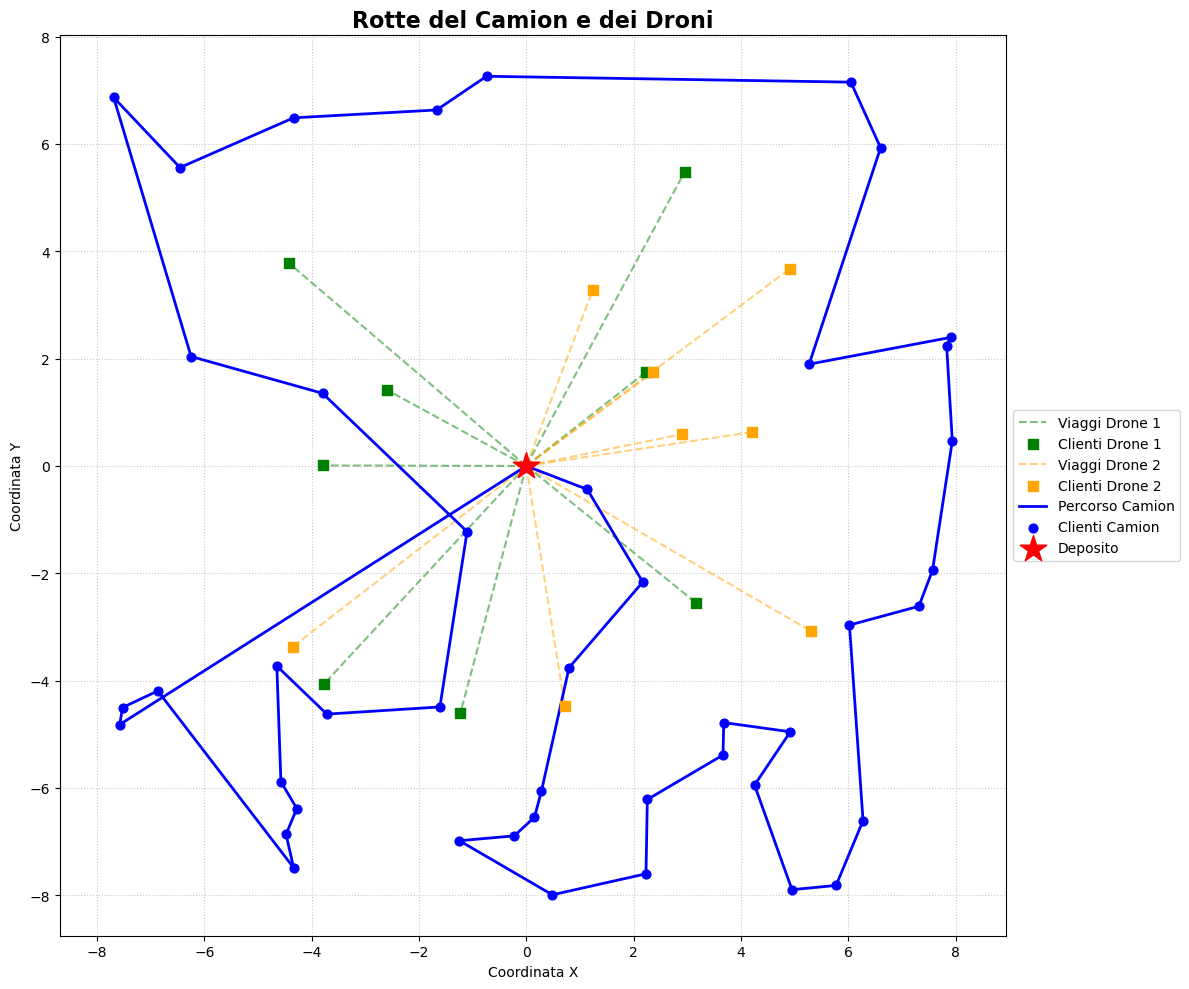

In [8]:
def visualizza_soluzione(coords, percorso_camion, assegnazioni_droni, num_clienti):
    """
    Disegna il grafo della soluzione mostrando il percorso del camion 
    e i viaggi di andata/ritorno dei droni dal deposito.
    """
    plt.figure(figsize=(12, 10))
    
    # Estrai coordinate del deposito
    x_depot, y_depot = coords[0]
    
    # 1. DISEGNO PERCORSI DRONI
    # Assegniamo colori diversi ai droni per la legenda
    colori_droni = ['green', 'orange', 'purple', 'cyan'] 
    
    for drone_id, clienti in assegnazioni_droni.items():
        colore = colori_droni[(drone_id - 1) % len(colori_droni)]
        
        # Disegna le linee tratteggiate dal deposito al cliente
        for i, cliente in enumerate(clienti):
            x_c, y_c = coords[cliente]
            # Evita di duplicare l'etichetta della linea nella legenda per ogni cliente
            label_linea = f'Viaggi Drone {drone_id}' if i == 0 else None
            plt.plot([x_depot, x_c], [y_depot, y_c], linestyle='--', color=colore, alpha=0.5, label=label_linea)
            
        # Disegna i nodi (clienti) assegnati a questo drone
        if clienti:
            x_nodi = [coords[c][0] for c in clienti]
            y_nodi = [coords[c][1] for c in clienti]
            plt.scatter(x_nodi, y_nodi, color=colore, marker='s', s=50, label=f'Clienti Drone {drone_id}', zorder=3)

    # 2. DISEGNO PERCORSO CAMION
    if percorso_camion:
        x_truck = [coords[n][0] for n in percorso_camion]
        y_truck = [coords[n][1] for n in percorso_camion]
        
        # Linea continua per il camion
        plt.plot(x_truck, y_truck, color='blue', linewidth=2, label='Percorso Camion', zorder=2)
        
        # Nodi (clienti) visitati dal camion (escludendo il deposito che ha id 0 e num_clienti+1)
        clienti_camion = [n for n in percorso_camion if n not in (0, num_clienti + 1)]
        x_c_truck = [coords[c][0] for c in clienti_camion]
        y_c_truck = [coords[c][1] for c in clienti_camion]
        plt.scatter(x_c_truck, y_c_truck, color='blue', marker='o', s=40, label='Clienti Camion', zorder=3)

    # 3. DISEGNO DEPOSITO
    plt.scatter(x_depot, y_depot, color='red', marker='*', s=400, label='Deposito', zorder=5)

    # 4. CONFIGURAZIONI GRAFICHE FINALI
    plt.title('Rotte del Camion e dei Droni', fontsize=16, fontweight='bold')
    plt.xlabel('Coordinata X')
    plt.ylabel('Coordinata Y')
    plt.grid(True, linestyle=':', alpha=0.7)
    
    # Posiziona la legenda fuori dal grafico principale per non coprire i nodi
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
    
    plt.axis('equal') # Mantiene le proporzioni degli assi
    plt.tight_layout()
    plt.show()

# Richiamo della funzione passando i dati generati nei blocchi precedenti
visualizza_soluzione(coords, percorso_finale, assegnazioni_droni, num_clienti)